# Chương 2 · Thực nghiệm và đánh giá

Notebook trình bày lại đúng bộ hình và bảng số liệu của Chương 2 trong báo cáo, kèm nhận xét cho từng thực nghiệm.

- **Số liệu** lấy từ các CSV trong `results/`, do `scripts/run_benchmark_grid.jl` đo (môi trường đo ở mục 0).
  Notebook **không chạy lại thực nghiệm**.
- **Hình** hiển thị từ file PNG có sẵn trong `results/figures/`, chính là hình trong báo cáo: hầu hết do
  `scripts/plot_results.jl` vẽ, riêng `peak_rss_basic_optimized` do `scripts/make_figures.jl` vẽ.
- **Bảng** do các hàm `*_table` của `scripts/make_figures.jl` tính từ CSV. Notebook đặt `FPCLOSE_SAVE_TABLES=0` và
  `FPCLOSE_SAVE_FIGURES=0` trước khi `include`, nên chỉ hiển thị, không ghi đè bảng LaTeX trong `docs/` hay hình trong
  `results/figures/`. Muốn sinh lại bảng cho báo cáo: `julia --project=scripts/plots scripts/make_figures.jl`.

**Cách chạy:** mở notebook với kernel Julia rồi *Run all*. Ô đầu tự kích hoạt môi trường `scripts/plots`
(chỉ có Plots.jl); lần đầu cài Plots mất vài phút.

**Quy ước:** thời gian là trung vị của 3 lần đo và **gồm đọc và ghi file** ở cả hai phía (SPMF: "Total time" tự in),
để so công bằng. Tỉ lệ thời gian $r = T_{\text{nhóm}} / T_{\text{SPMF}}$: $r < 0{,}90$ là nhóm nhanh hơn,
$0{,}90 \le r \le 1{,}10$ là gần tương đương, $r > 1{,}10$ là nhóm chậm hơn.

## 0 · Thiết lập và môi trường đo

In [1]:
using Pkg
# Thư mục gốc repo: nơi có src/FPClose.jl và scripts/make_figures.jl
function find_repo(dir = pwd())
    while true
        isfile(joinpath(dir, "scripts", "make_figures.jl")) && return dir
        parent = dirname(dir)
        parent == dir && error("Không tìm thấy repo FPClose: mở notebook từ trong repo")
        dir = parent
    end
end
REPO_DIR = find_repo()
# Chỉ đọc và hiển thị: không ghi bảng LaTeX vào docs/, không ghi hình vào results/figures/ (đặt TRƯỚC khi include)
ENV["FPCLOSE_SAVE_TABLES"] = "0"
ENV["FPCLOSE_SAVE_FIGURES"] = "0"
Pkg.activate(joinpath(REPO_DIR, "scripts", "plots"); io = devnull)
Pkg.instantiate()
include(joinpath(REPO_DIR, "scripts", "make_figures.jl"))

const FIG_DIR = joinpath(REPO_DIR, "results", "figures")
show_md(s) = display("text/markdown", s)
"Hiển thị hình có sẵn results/figures/<name>.png (đúng hình trong báo cáo)."
show_figure(name) = display(MIME("image/png"), read(joinpath(FIG_DIR, name * ".png")))
show_md(read(joinpath(REPO_DIR, "results", "ENVIRONMENT.md"), String))

# Môi trường chạy thực nghiệm

Ghi tự động bởi `scripts/run_benchmark_grid.jl` ở lần chạy gần nhất (mỗi dòng của các CSV có cột `machine`).

| Mục | Giá trị |
|---|---|
| Cập nhật lúc (UTC) | 2026-11-24 00:31:29 |
| Nhãn máy | MSI |
| Hệ điều hành | NT (x86_64-w64-mingw32) |
| CPU | AMD Ryzen 9 8940HX with Radeon Graphics         |
| Số luồng logic | 32 |
| RAM | 15.2 GiB |
| Julia | 1.13.4 |
| Java | openjdk version "25.0.5.1" 2026-11-17 LTS |
| spmf.jar SHA-256 | `bb371b99b3bfd58fbce6b92e0ea3ccda5f9d1fd173bfe8e40f177672117159ba` |
| JVM heap (-Xmx) | 4g |
| Commit | 5434a47 (có thay đổi chưa commit) |
| Số lần đo mỗi cấu hình | 3 (tổng hợp lấy nhỏ nhất) |
| Timeout mỗi lần chạy | 600 s |
| Chế độ | đầy đủ |

Chưa ghi tự động (cần ghi tay trước khi chạy chính thức): chế độ nguồn/hiệu năng của máy, ứng dụng nền đang mở,
nhiệt độ. Mọi số liệu trên cùng một biểu đồ phải đo trên cùng máy.


## 1 · Correctness

**Đề:** với mỗi tập dữ liệu, so số lượng frequent itemset và support của từng itemset giữa cài đặt của nhóm và SPMF;
báo cáo tỉ lệ itemset khớp hoàn toàn; nếu có sai lệch thì phân tích nguyên nhân.

**Cách đo:** 56 cấu hình (9 dataset × 6–7 mức minsup). So **closed itemsets** của `fpclose` với SPMF `FPClose` ở mọi
cấu hình, và **mọi frequent itemset** (khôi phục từ tập đóng) với SPMF `FPGrowth_itemsets` ở mọi mức minsup có không
quá 2 triệu frequent itemset (`--fi-all-levels`, `--fi-limit 2000000`).

Tỉ lệ khớp = itemset khớp (cùng itemset, cùng support) / số itemset khác nhau của cả hai phía, cộng dồn mọi cấu hình
(nguồn: `results/correctness/grid_correctness_fi_all_levels.csv`).

In [2]:
show_md(correctness_table())

| Dataset | Số mức minsup | Closed khớp/tổng | Tỉ lệ closed | Mức so mọi FI | Mọi FI khớp/tổng | Tỉ lệ mọi FI |
|---|---:|---:|---:|---:|---:|---:|
| chess | 7 | 190 309/190 309 | 100,00% | 7/7 | 447 425/447 425 | 100,00% |
| mushrooms | 7 | 83 281/83 281 | 100,00% | 4/7 | 2 083 190/2 083 190 | 100,00% |
| connect | 6 | 87 877/87 877 | 100,00% | 5/6 | 2 290 981/2 290 981 | 100,00% |
| pumsb_star | 6 | 9 785/9 785 | 100,00% | 6/6 | 146 929/146 929 | 100,00% |
| accidents | 6 | 43 368/43 368 | 100,00% | 6/6 | 43 368/43 368 | 100,00% |
| retail | 6 | 95 417/95 417 | 100,00% | 6/6 | 97 447/97 447 | 100,00% |
| T10I4D100K | 6 | 196 186/196 186 | 100,00% | 6/6 | 225 505/225 505 | 100,00% |
| T40I10D100K | 6 | 88 637/88 637 | 100,00% | 6/6 | 88 637/88 637 | 100,00% |
| kosarak | 6 | 54 138/54 138 | 100,00% | 6/6 | 57 830/57 830 | 100,00% |
| Tổng | 56 | 848 998/848 998 | 100,00% | 52/56 | 5 481 312/5 481 312 | 100,00% |


### Nhận xét

- **Closed itemset:** cài đặt của nhóm khớp SPMF 100% ở cả 56/56 cấu hình, tổng cộng 848.998 itemset được đối chiếu;
  không có itemset thừa, thiếu hay lệch support.
- **Mọi frequent itemset:** tập khôi phục từ tập đóng khớp 100% với `FPGrowth_itemsets` ở 52/56 cấu hình
  (5.481.312 itemset). Bốn cấu hình còn lại (mushrooms 5%, 3%, 2% và connect 70%) vượt giới hạn 2 triệu frequent
  itemset nên không so trực tiếp.
- Số frequent itemset bùng nổ nhanh hơn nhiều so với số tập đóng (mushrooms 20%: 53.583 frequent itemset so với 1.197
  tập đóng). Đây là lý do khai thác tập đóng rồi khôi phục khi cần.
- Bản thân SPMF được kiểm tra trước khi dùng làm đáp án: trên cả 56 cấu hình, kết quả của SPMF giống từng itemset và
  support với cài đặt FPclose gốc của các tác giả trong kho FIMI.
- Sai khác duy nhất từng gặp là phép làm tròn minsup bằng số thực dấu phẩy động ($0{,}07 \times 100$ được biểu diễn là
  $7{,}000000000000001$ nên ngưỡng thành 8); nhóm dùng quy ước tương thích SPMF. Bộ kiểm thử tự động đạt 28.266/28.266 ca.

## 2 · Thời gian chạy theo minsup

**Đề:** với mỗi tập dữ liệu, vẽ thời gian chạy theo minsup giảm dần (5–7 điểm), so đường cong của nhóm và SPMF trên
cùng đồ thị.

**Cách đo:** `results/runtime/grid_runtime.csv` (mỗi dòng một lần đo), lấy trung vị cột `time_with_write_s` của
3 lần đo cho mỗi (dataset, minsup, công cụ). Mỗi hình một CSDL như bài báo gốc: trục hoành là các mức minsup đặt
**cách đều theo thứ tự**, giảm dần từ trái sang phải (khoảng cách ngang không tỉ lệ với giá trị minsup); trục tung
thang log.

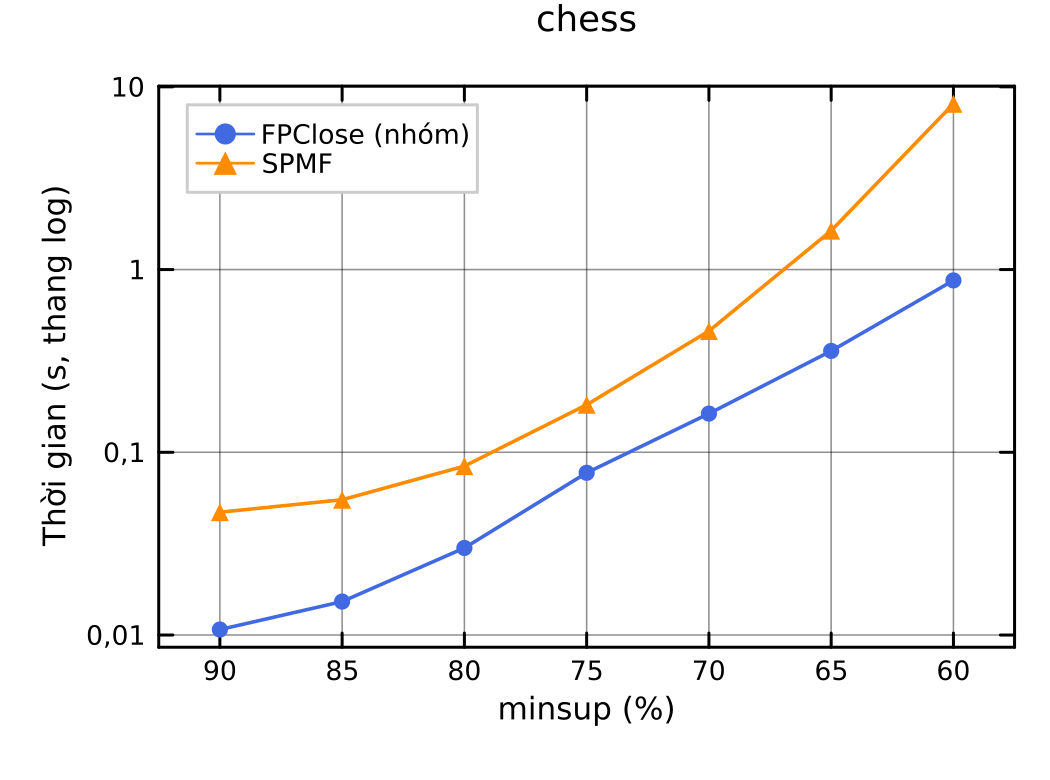

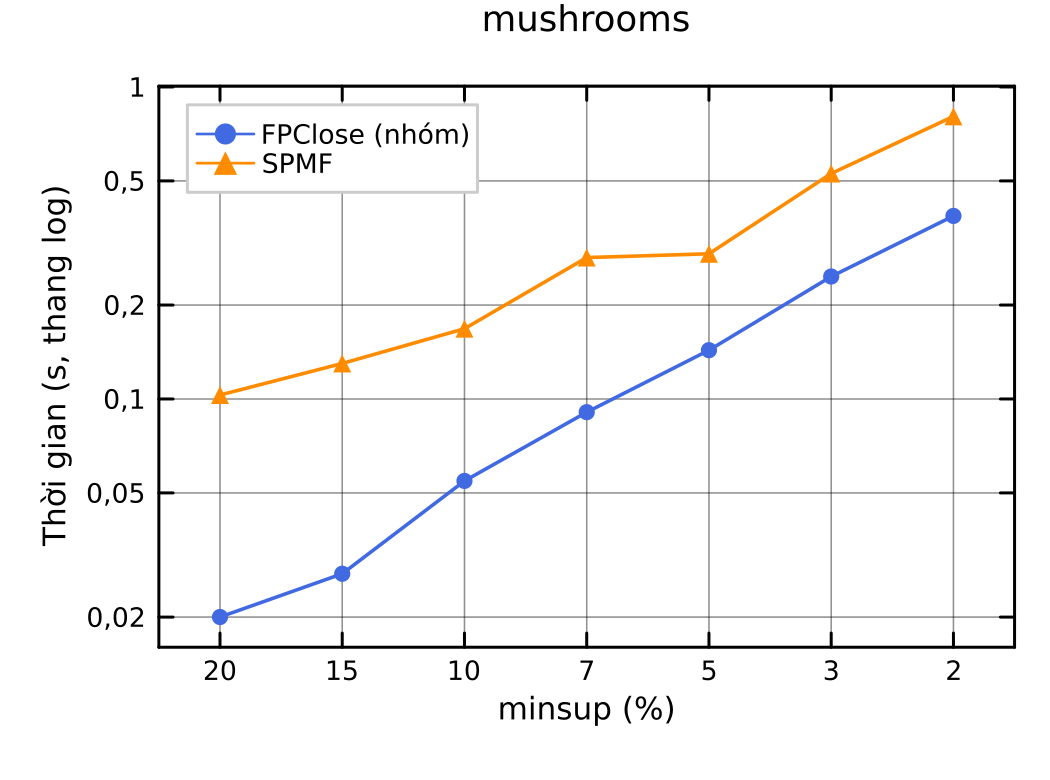

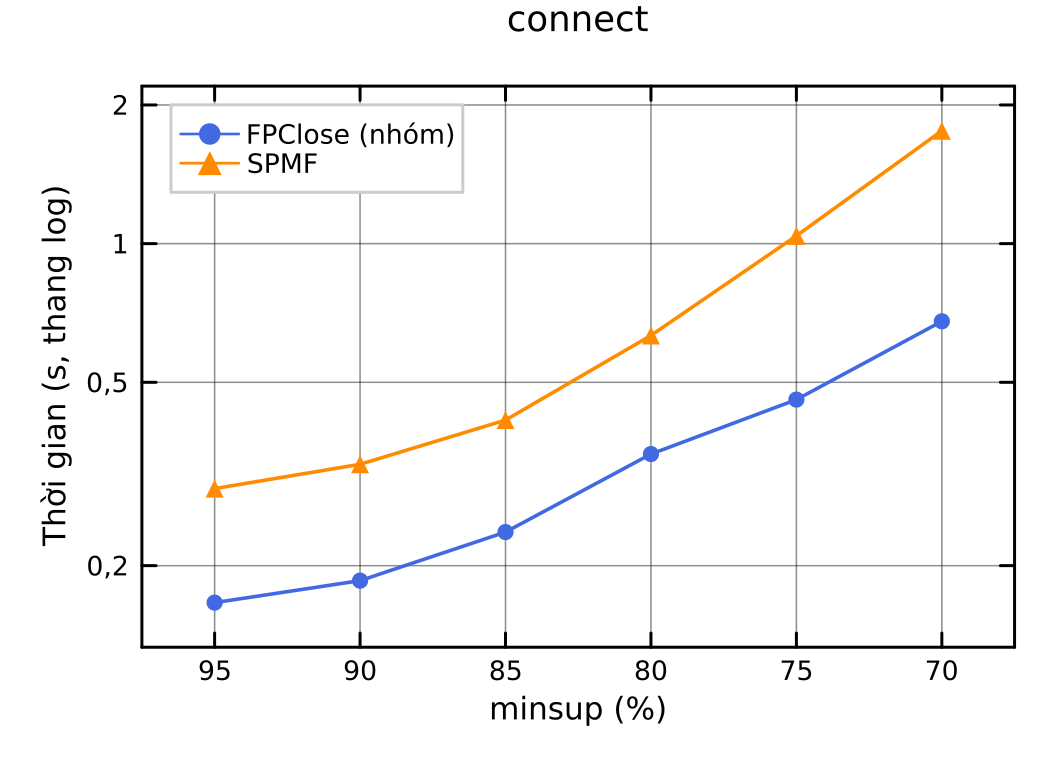

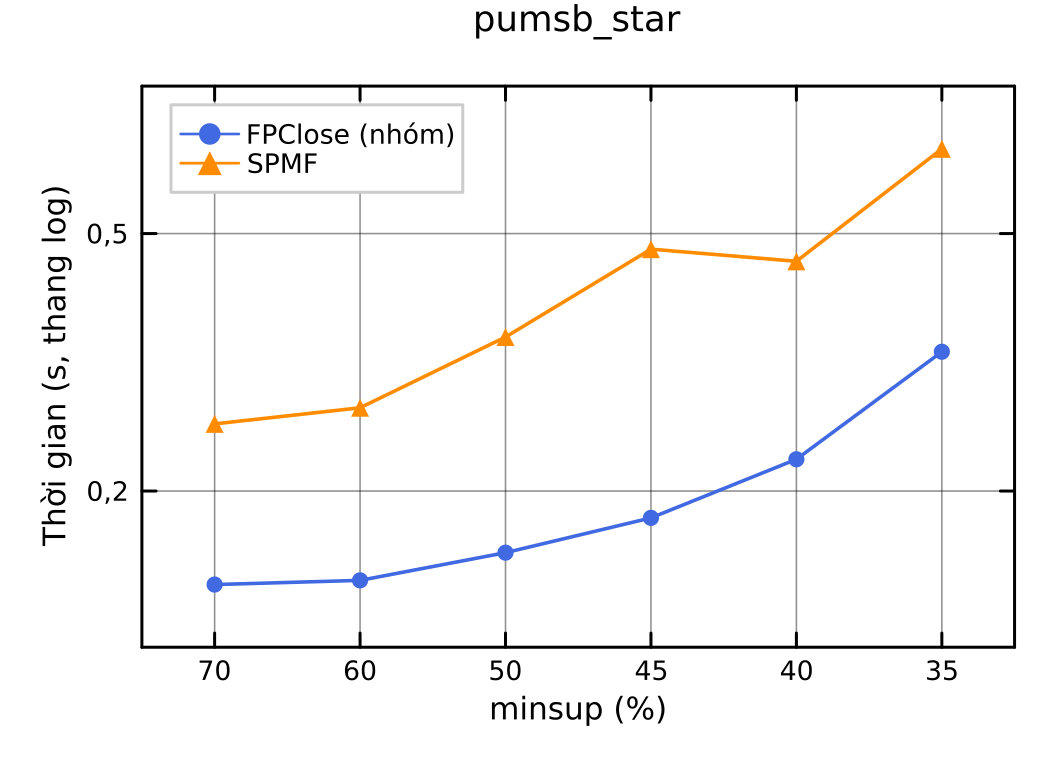

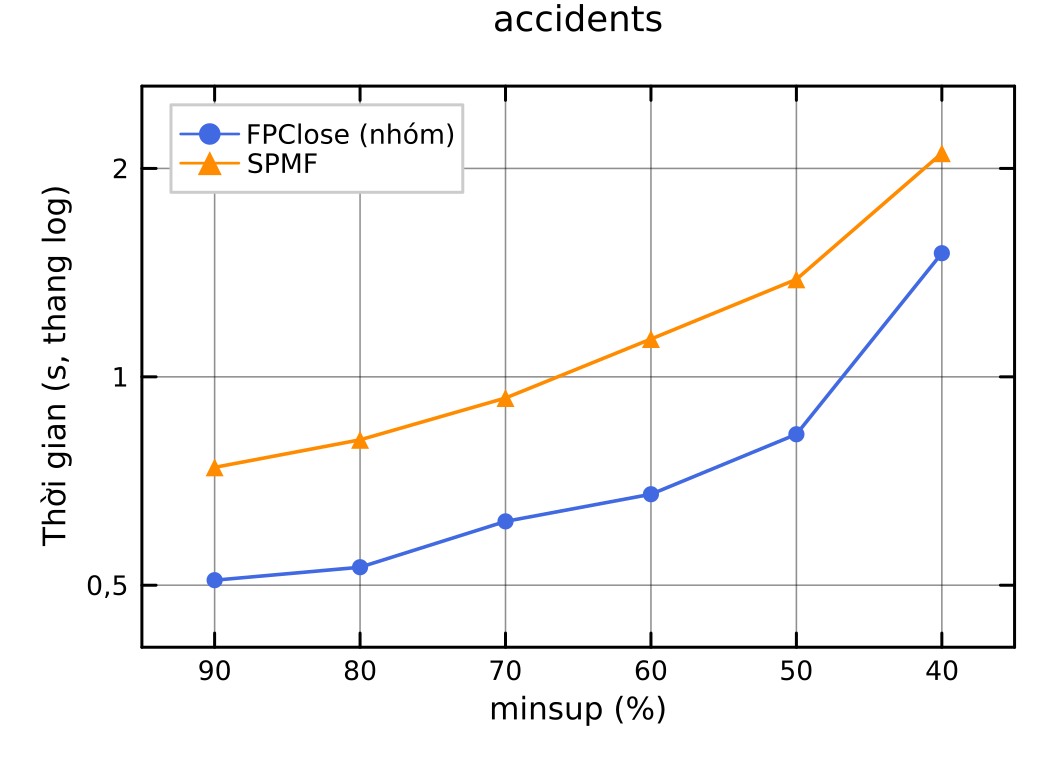

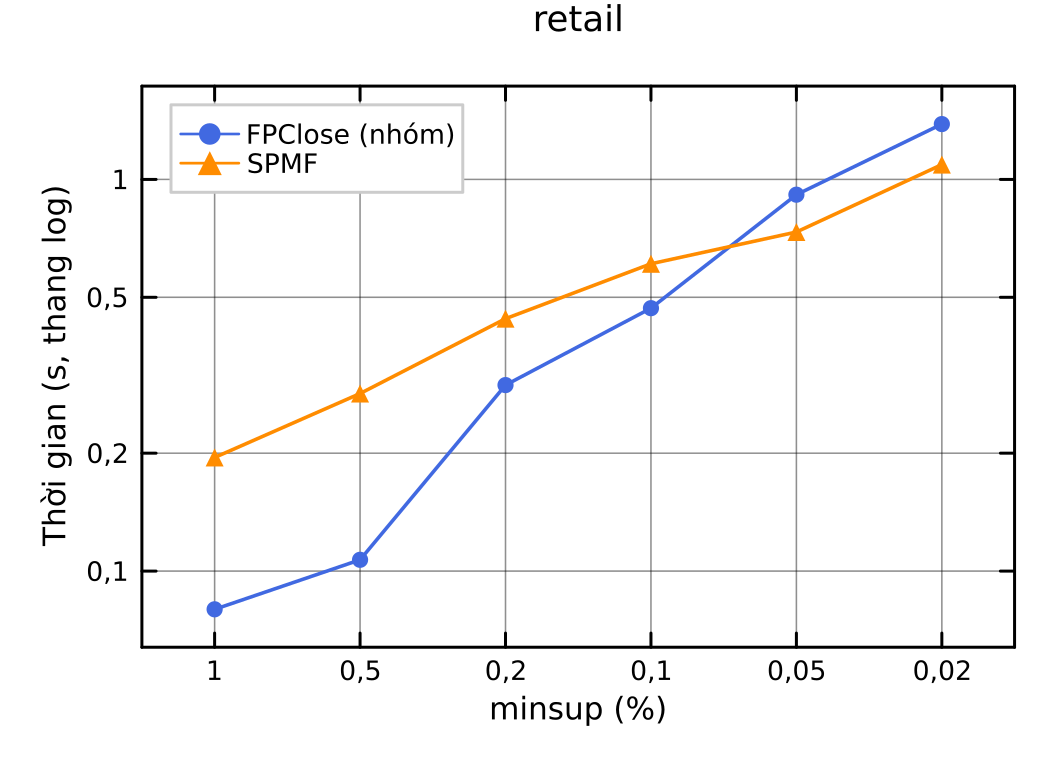

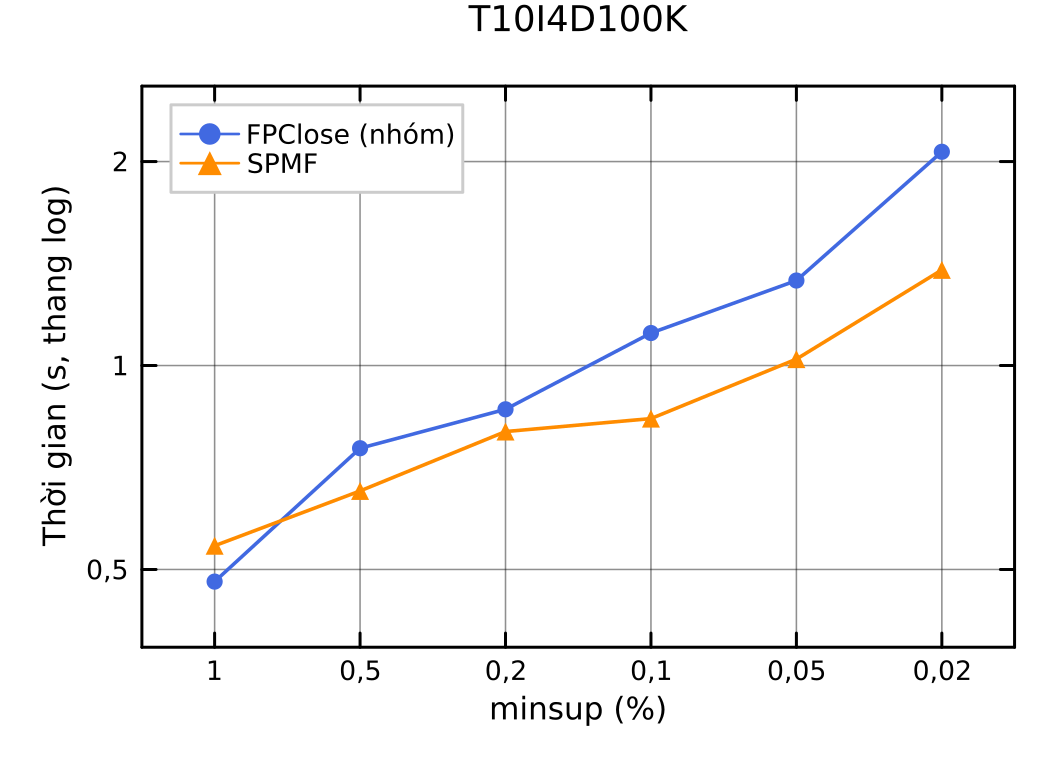

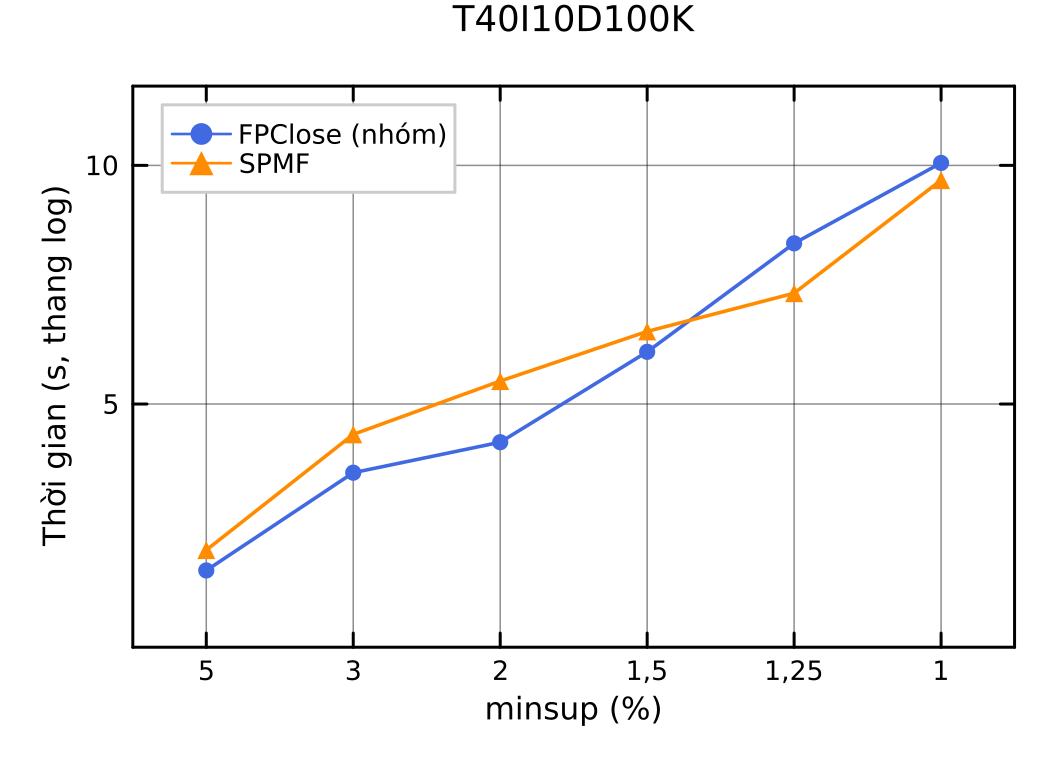

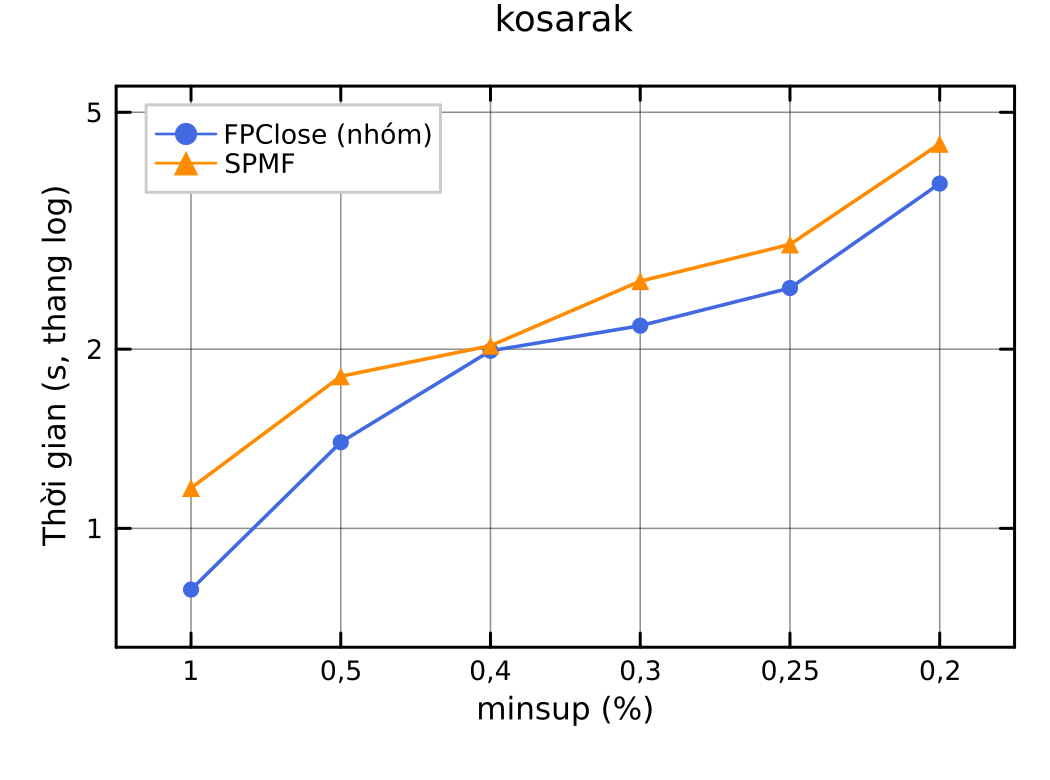

In [3]:
for d in ["chess", "mushrooms", "connect", "pumsb_star", "accidents", "retail", "T10I4D100K", "T40I10D100K", "kosarak"]
    show_figure("runtime_" * d)
end

### Tỉ lệ thời gian nhóm / SPMF

Mỗi ô là $r = T_{\text{nhóm}} / T_{\text{SPMF}}$ tại một mức minsup (M1 là mức cao nhất). Nhỏ hơn 1 nghĩa là nhóm
nhanh hơn SPMF.

In [4]:
show_md(runtime_ratio_table())

| Dataset | minsup | M1 | M2 | M3 | M4 | M5 | M6 | M7 |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| chess | 90%–60% | 0,23 | 0,28 | 0,36 | 0,42 | 0,35 | 0,22 | 0,11 |
| mushrooms | 20%–2% | 0,19 | 0,21 | 0,33 | 0,32 | 0,49 | 0,47 | 0,48 |
| connect | 95%–70% | 0,57 | 0,56 | 0,57 | 0,55 | 0,44 | 0,39 |  |
| pumsb_star | 70%–35% | 0,56 | 0,54 | 0,46 | 0,38 | 0,49 | 0,49 |  |
| accidents | 90%–40% | 0,69 | 0,65 | 0,66 | 0,60 | 0,60 | 0,72 |  |
| retail | 1%–0,02% | 0,41 | 0,38 | 0,68 | 0,77 | 1,25 | 1,27 |  |
| T10I4D100K | 1%–0,02% | 0,89 | 1,16 | 1,08 | 1,34 | 1,31 | 1,49 |  |
| T40I10D100K | 5%–1% | 0,94 | 0,89 | 0,84 | 0,94 | 1,16 | 1,05 |  |
| kosarak | 1%–0,2% | 0,68 | 0,77 | 0,98 | 0,84 | 0,84 | 0,86 |  |


### Phân rã thời gian của nhóm

Tại minsup thấp nhất của mỗi CSDL, thời gian của nhóm được chia thành đọc file, dựng FP-tree và khai thác, ghi file
(cột `read_s`, `mine_s`, `write_s` của `grid_runtime.csv`; `mine_s` gồm cả dựng FP-tree).

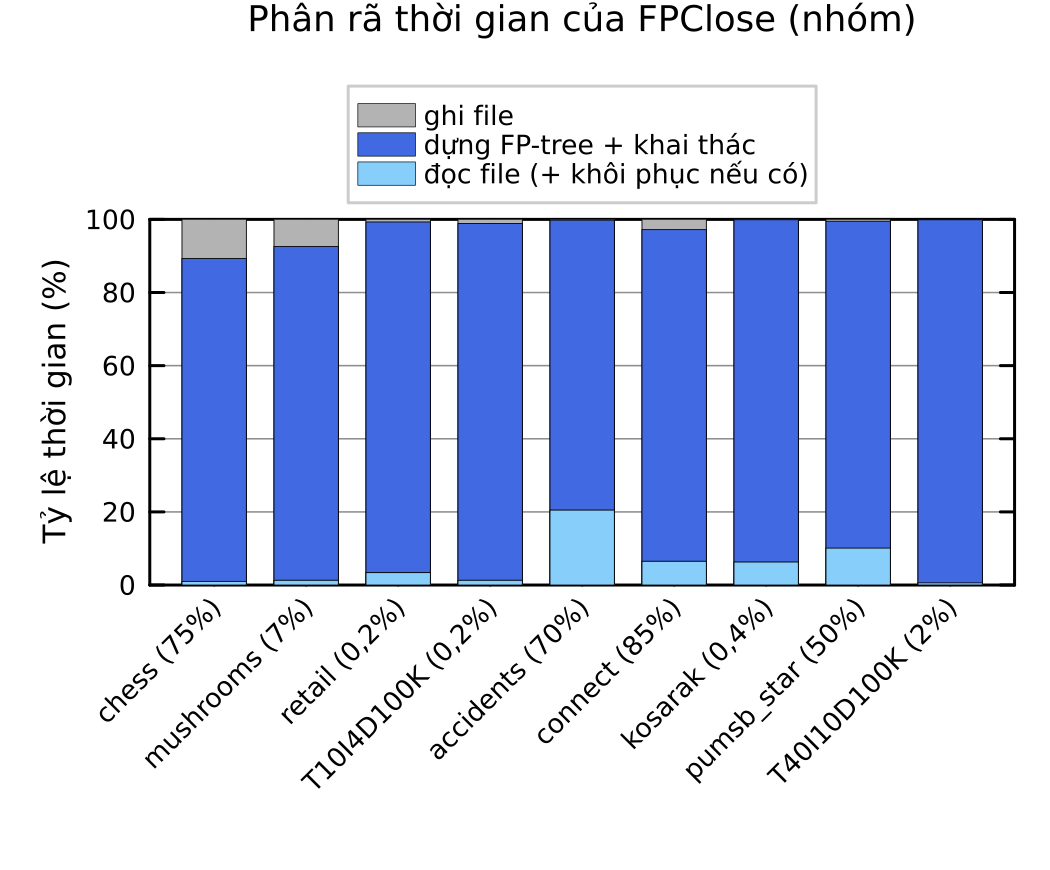

| Dataset | minsup | Đọc | Khai thác | Ghi | Tổng nhóm | SPMF | Tổng / SPMF | Khai thác / tổng SPMF |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| chess | 60% | 0,001 | 0,766 | 0,105 | 0,872 | 8,071 | 0,11 | 0,09 |
| mushrooms | 2% | 0,001 | 0,356 | 0,030 | 0,386 | 0,805 | 0,48 | 0,44 |
| connect | 70% | 0,015 | 0,625 | 0,038 | 0,678 | 1,758 | 0,39 | 0,36 |
| pumsb_star | 35% | 0,016 | 0,307 | 0,005 | 0,328 | 0,676 | 0,49 | 0,45 |
| accidents | 40% | 0,114 | 1,298 | 0,096 | 1,509 | 2,104 | 0,72 | 0,62 |
| retail | 0,02% | 0,010 | 1,328 | 0,046 | 1,384 | 1,091 | 1,27 | 1,22 |
| T10I4D100K | 0,02% | 0,011 | 1,973 | 0,085 | 2,068 | 1,384 | 1,49 | 1,43 |
| T40I10D100K | 1% | 0,027 | 10,000 | 0,045 | 10,072 | 9,581 | 1,05 | 1,04 |
| kosarak | 0,2% | 0,126 | 3,644 | 0,025 | 3,795 | 4,426 | 0,86 | 0,82 |


In [5]:
show_figure("time_breakdown")
show_md(runtime_breakdown_table())

### Nhận xét

- Theo quy ước ngưỡng, trên 56 cấu hình nhóm nhanh hơn SPMF ở 44, gần tương đương ở 5 và chậm hơn ở 7.
- **Dữ liệu dày:** nhóm nhanh hơn ở mọi mức minsup: chess (tỉ lệ 0,11–0,42), mushrooms (0,19–0,49), connect
  (0,39–0,57), pumsb_star (0,38–0,56), accidents (0,60–0,72). Trên chess khoảng cách tăng khi minsup giảm: ở 60%, nhóm
  mất 0,87 s so với 8,07 s của SPMF.
- **Dữ liệu thưa:** kosarak nhanh hơn ở năm trên sáu mức (0,68–0,86). Retail nhanh hơn từ 1% đến 0,1% (0,38–0,77) nhưng
  chậm hơn ở 0,05% và 0,02% (1,25 và 1,27); T10I4D100K chậm hơn ở phần lớn các mức (1,16–1,49); T40I10D100K nằm trong
  khoảng 0,84–1,16.
- **Phân rã:** tại minsup thấp nhất, đọc file chiếm khoảng 7,6% trên accidents, 4,9% trên pumsb_star và dưới 3,5% trên
  các CSDL còn lại; dựng FP-tree và khai thác chiếm khoảng 86–99%. Đây là thành phần cần ưu tiên cải tiến.
- Các cấu hình nhóm chậm hơn đều ở dữ liệu thưa với minsup thấp, nơi FP-tree nén kém: tỉ lệ kích thước FP-tree
  $R_{\text{tree}}$ là 56–89% ở retail, T10I4D100K và T40I10D100K, so với dưới 11% ở dữ liệu dày.

## 3 · Số lượng itemset theo minsup

**Đề:** vẽ số lượng itemset sinh ra theo minsup; nhận xét quan hệ giữa minsup và output size, so sánh dữ liệu dày và thưa.

**Cách đo:** hình `itemsets_vs_minsup` có hai ô cạnh nhau, cùng màu và marker cho mỗi CSDL:
- **(a) Số frequent itemset:** cột `n_ours` (số frequent itemset do nhóm khôi phục từ tập đóng) của
  `results/correctness/grid_correctness_fi_all_levels.csv`, các dòng `mode = all_fi` và `status = OK` (52/56 cấu hình,
  đều có `n_ours = n_spmf`). Bốn cấu hình vượt giới hạn 2 triệu frequent itemset (mushrooms 5%, 3%, 2% và connect 70%)
  không được vẽ.
- **(b) Số closed frequent itemset:** ở mỗi cấu hình (đã khớp SPMF 100% ở mục 1), lấy từ `grid_runtime.csv`.

Hai trục đều thang log, hai ô dùng chung giới hạn trục tung để so độ lớn; trục hoành là minsup thật (%) nên mỗi CSDL
nằm ở một khoảng minsup riêng.

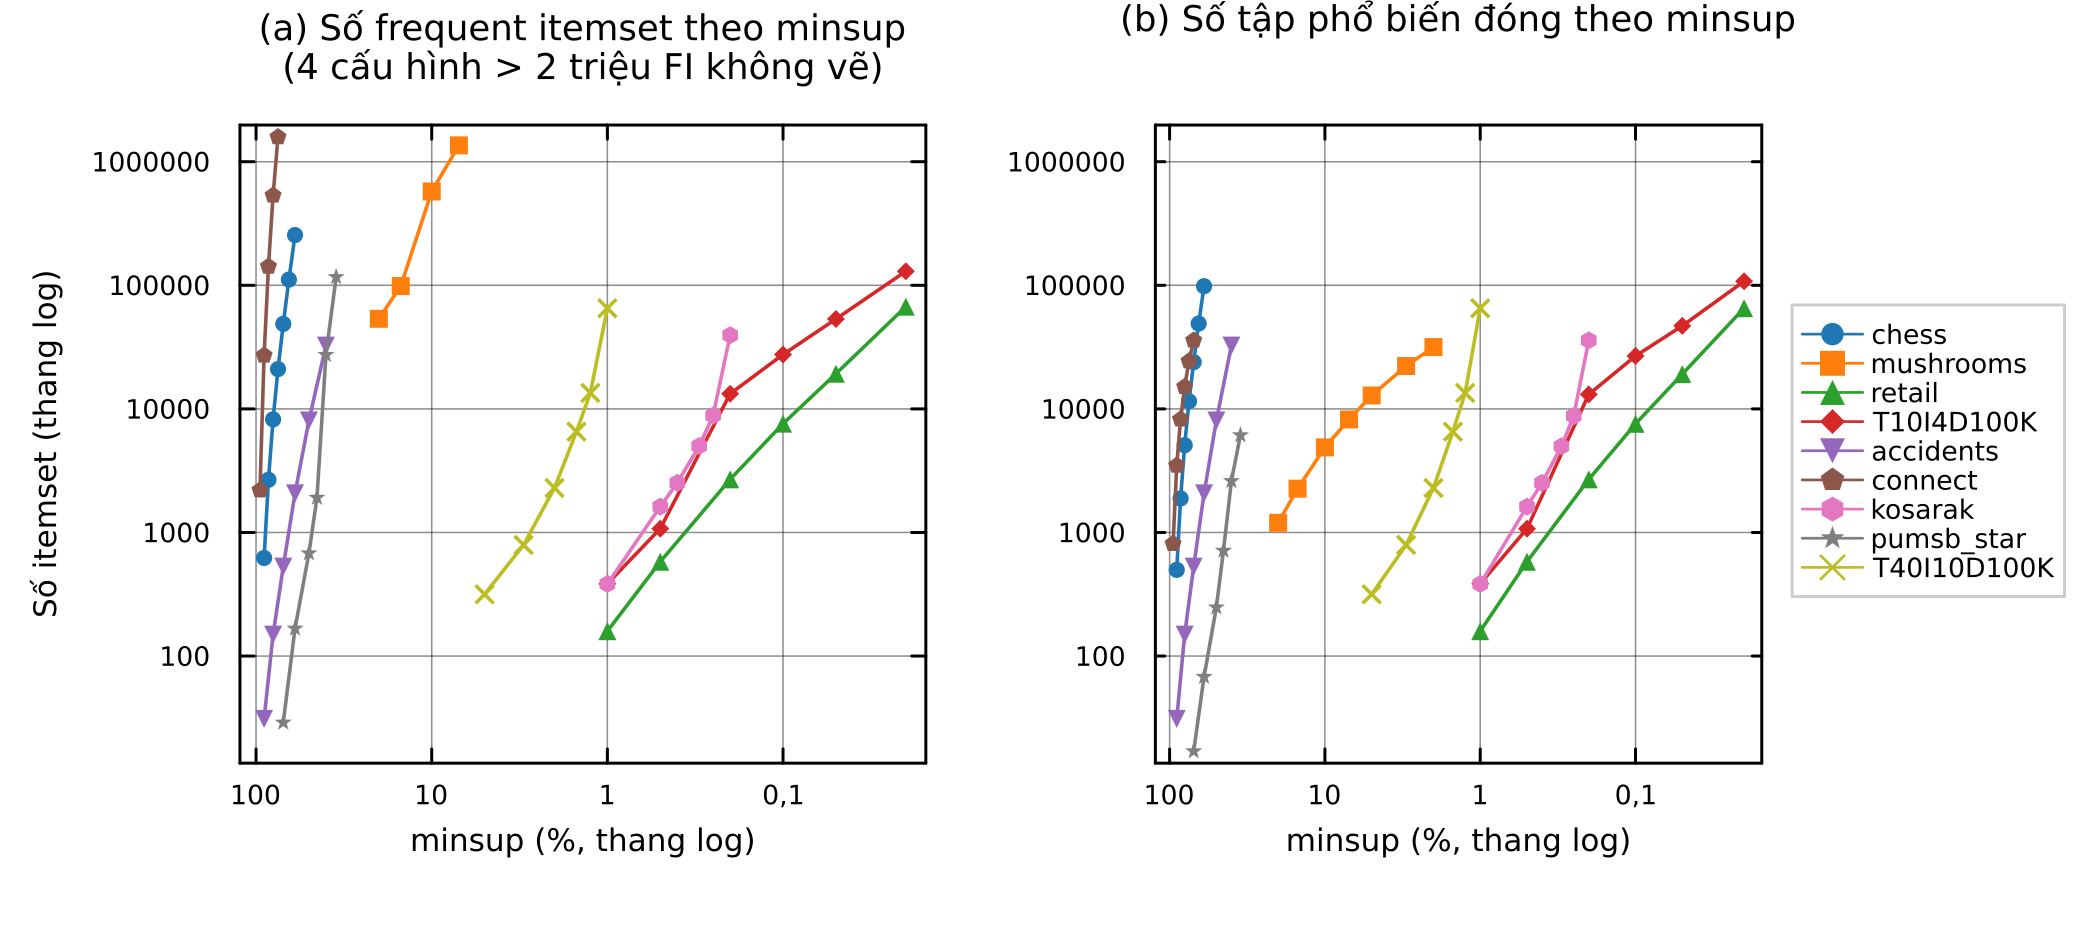

In [6]:
show_figure("itemsets_vs_minsup")

### Nhận xét

- Khi minsup giảm, số tập đóng tăng nhanh ở cả dữ liệu dày và thưa: chess từ 498 tập (90%) lên 98.392 tập (60%),
  accidents từ 31 (90%) lên 32.528 (40%).
- Dữ liệu thưa chỉ có output lớn ở ngưỡng thấp hơn nhiều: retail từ 159 tập (1%) lên 65.301 tập (0,02%), T10I4D100K
  từ 385 lên 107.822.
- **Frequent itemset (ô a):** trên dữ liệu dày, số frequent itemset lớn hơn số tập đóng nhiều lần: mushrooms 20% có
  53.583 frequent itemset so với 1.197 tập đóng (khoảng 45 lần), cao nhất là mushrooms 7% với 1.356.601 so với 8.212
  (khoảng 165 lần); riêng accidents có hai số bằng nhau ở cả 6 mức minsup. Trên dữ liệu thưa, hai số gần như trùng nhau:
  14/24 cấu hình có tỉ lệ đúng bằng 1 và tỉ lệ lớn nhất chỉ khoảng 1,2 (T10I4D100K 0,02%: 129.875 so với 107.822). Lợi
  ích nén của biểu diễn tập đóng vì vậy chủ yếu thể hiện trên dữ liệu dày.
- Khác biệt giữa hai nhóm liên quan đến phân bố và mức đồng xuất hiện của item: dữ liệu dày phát sinh nhiều tập đóng
  ngay tại các ngưỡng hỗ trợ tương đối cao.
- Kích thước đầu ra có liên quan đến thời gian chạy (mục 2) nhưng không phải yếu tố duy nhất, vì thời gian còn phụ
  thuộc cấu trúc cây và hiệu quả cắt nhánh. Lưới minsup vì vậy được chọn riêng cho từng CSDL (60–95% cho chess và
  connect, 0,02–1% cho retail và T10I4D100K).

## 4 · Bộ nhớ: bản cơ bản và bản tối ưu

**Đề:** đo và báo cáo RAM tối đa (peak memory) cho mỗi tập dữ liệu tại minsup trung bình; so sánh bản cơ bản và bản
tối ưu của nhóm.

**Cách đo:** `results/memory/basic_vs_optimized.csv`, tại minsup giữa lưới của mỗi CSDL. Mỗi biến thể chạy 3 lần
trong tiến trình Julia riêng; lấy trung vị.
- Biến thể: **basic** tắt cả năm tối ưu; **pruning-only** chỉ bật cắt nhánh dòng 8 (khóa `paper` trong CSV);
  **optimized** bật cả năm (cắt nhánh, FP-array, kết thúc sớm, so count chính xác, CFI-tree rút gọn); năm biến thể
  "Không …" lần lượt tắt riêng một tối ưu của bản optimized.
- **Hình `peak_rss_basic_optimized`:** RAM tối đa của cả tiến trình (cột `peak_mem_mb`, gồm khoảng 285 MB nền của
  Julia) của basic và optimized; đường nét đứt là mức đo ngay sau warm-up.
- **Hình `memory_variants_grid`:** RAM tối đa tăng thêm so với mức sau warm-up (cột `mem_delta_mb` = peak − baseline)
  của cả tám biến thể.
- Chỉ so các biến thể của nhóm với nhau: "Max memory" của SPMF là heap JVM, đo khác RSS.

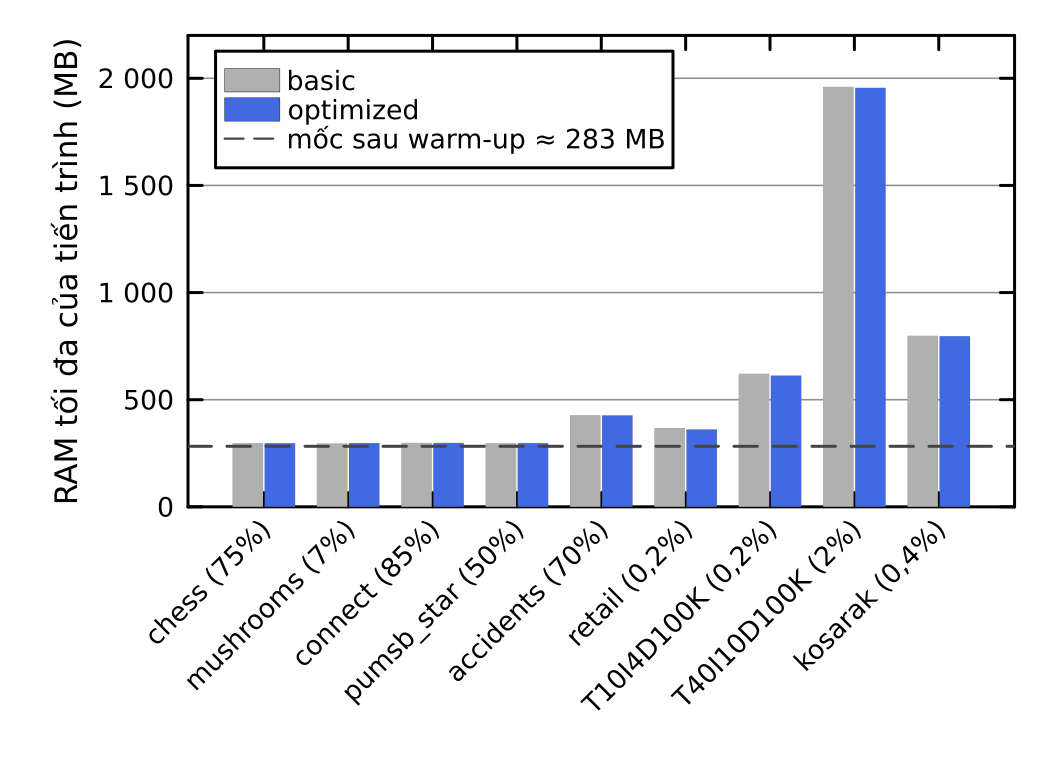

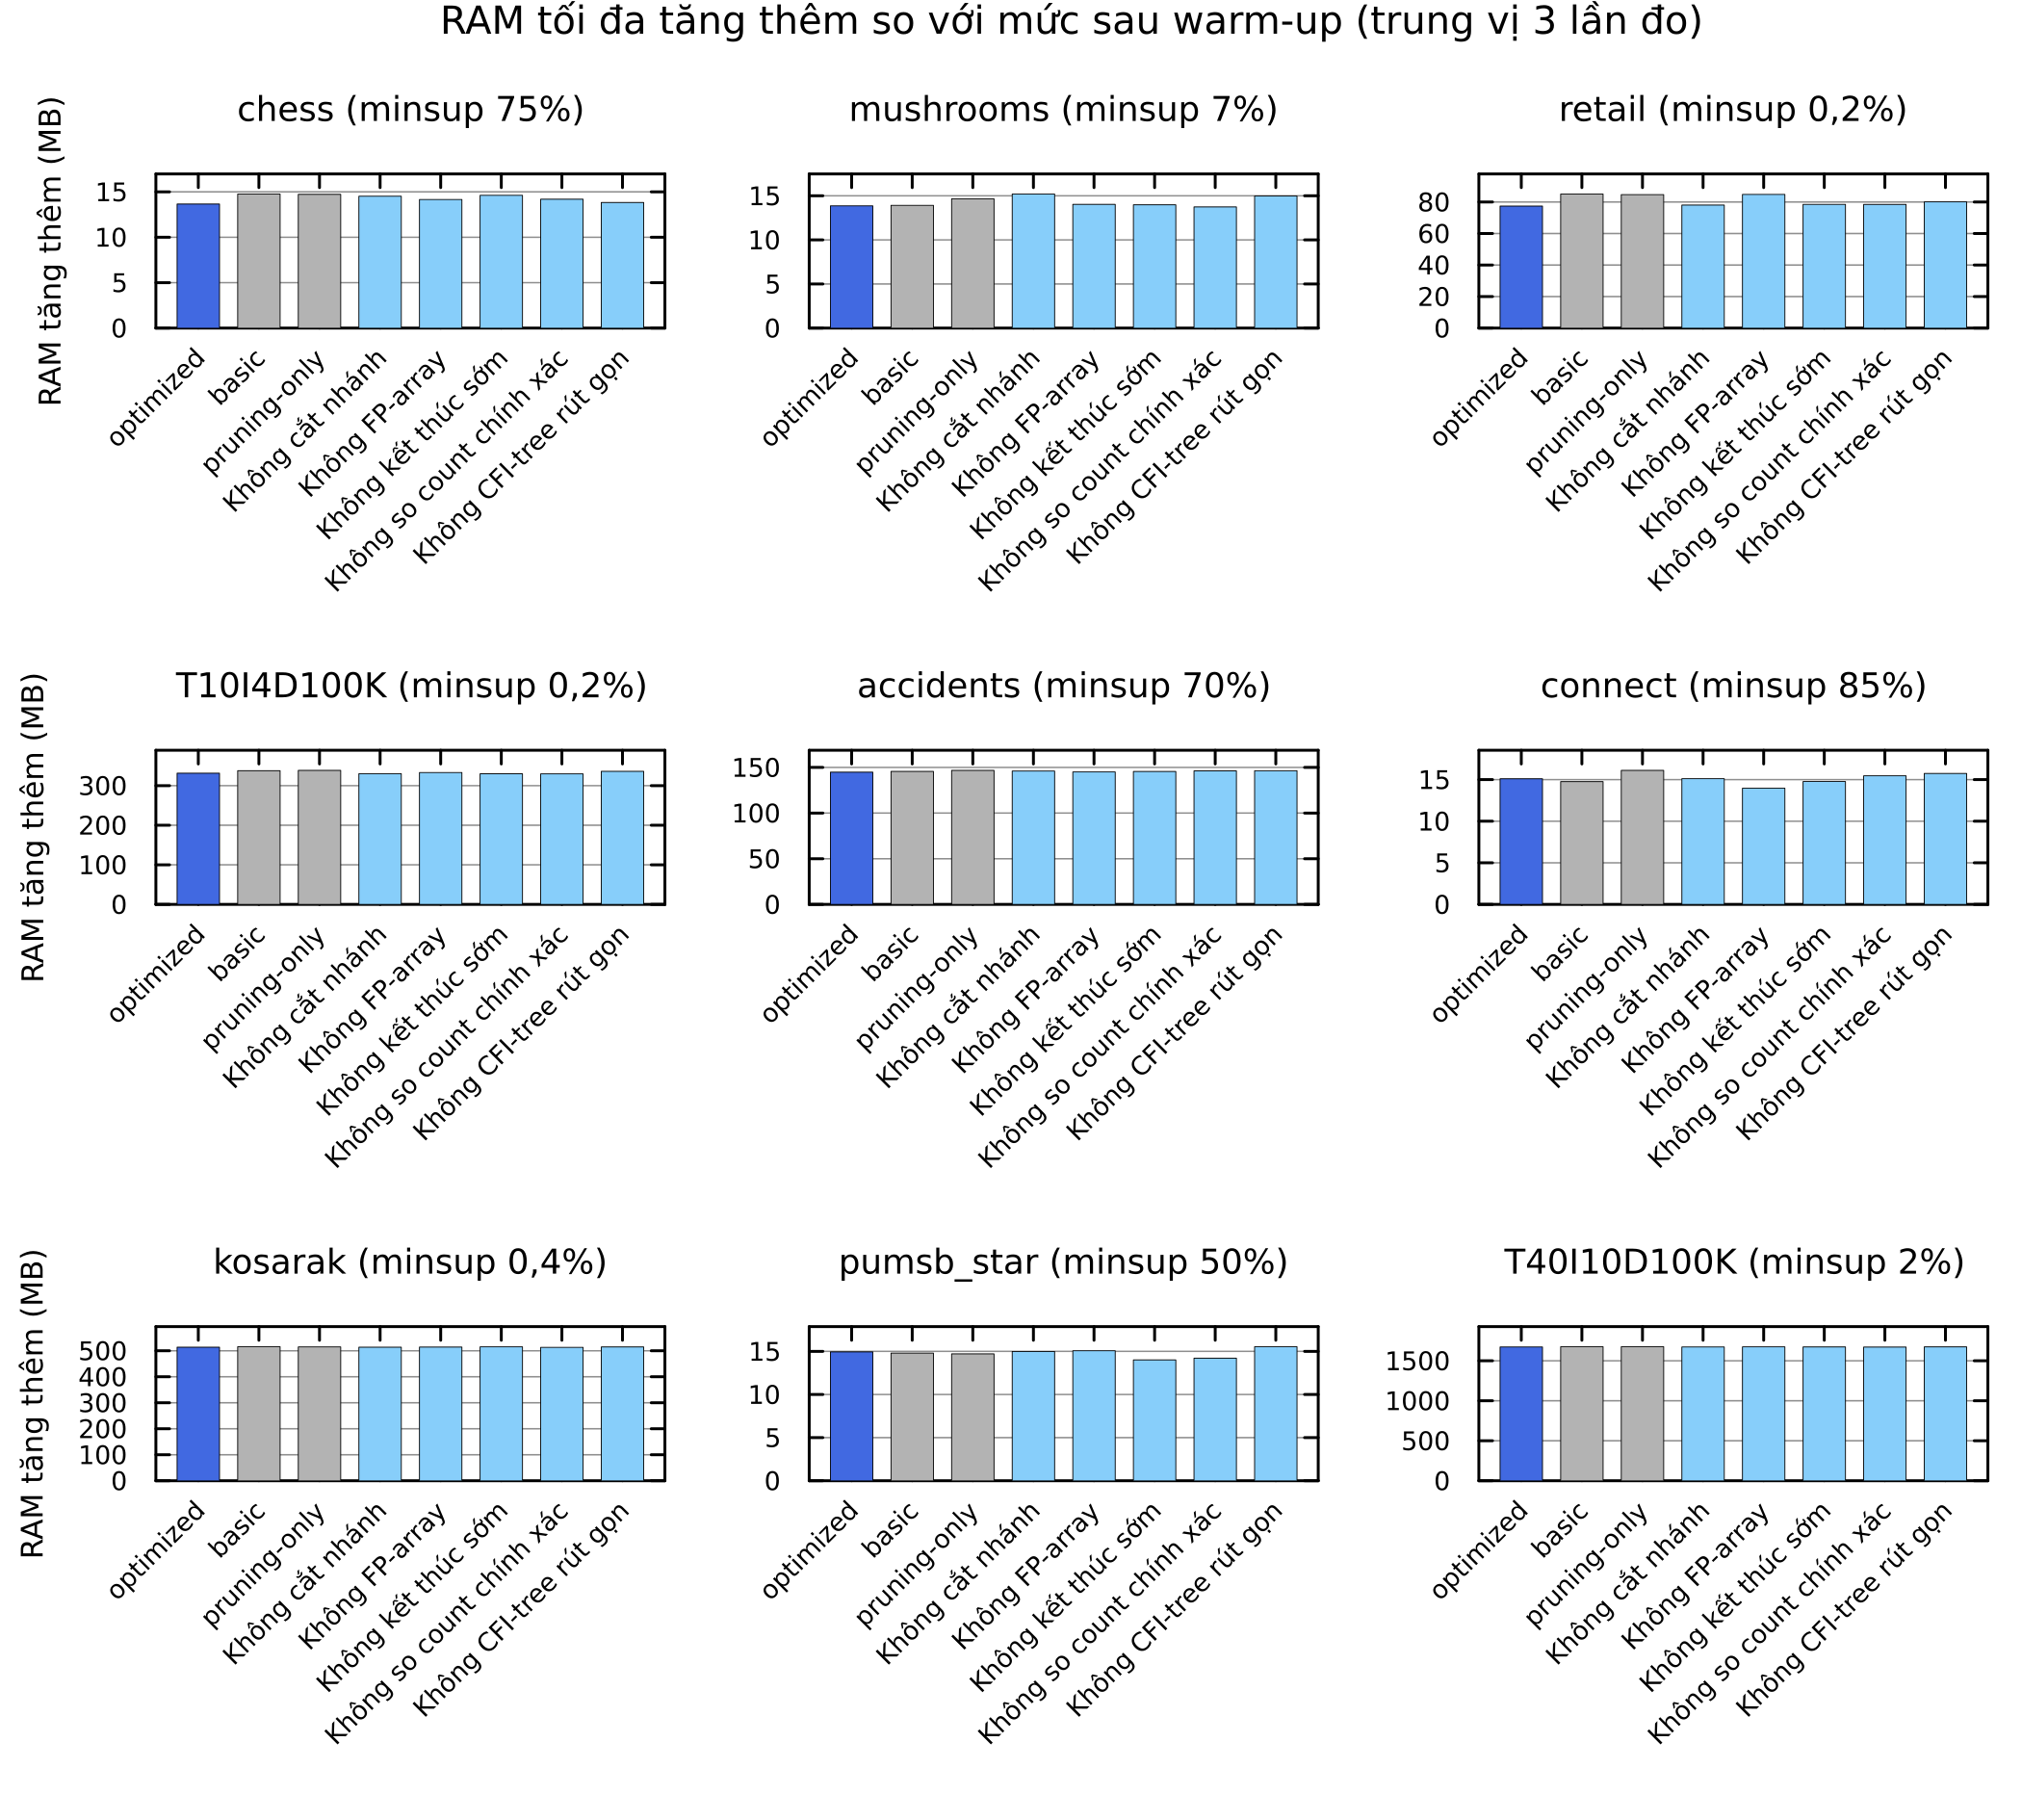

In [7]:
show_figure("peak_rss_basic_optimized")
show_figure("memory_variants_grid")

In [8]:
tables = memory_tables()
show_md(tables.memory)

| Dataset | minsup | Biến thể | RAM tối đa (MB) | Tăng thêm (MB) | Cấp phát (MB) | Khai thác (s) |
|---|---|---|---:|---:|---:|---:|
| chess | 75% | basic | 297 | 14,8 | 124 | 0,086 |
|  |  | pruning-only | 296 | 14,7 | 123 | 0,087 |
|  |  | optimized | 297 | 13,7 | 111 | 0,071 |
| mushrooms | 7% | basic | 295 | 13,9 | 197 | 0,121 |
|  |  | pruning-only | 296 | 14,7 | 144 | 0,092 |
|  |  | optimized | 297 | 13,9 | 136 | 0,084 |
| connect | 85% | basic | 298 | 14,8 | 517 | 0,248 |
|  |  | pruning-only | 298 | 16,1 | 488 | 0,238 |
|  |  | optimized | 298 | 15,1 | 479 | 0,230 |
| pumsb_star | 50% | basic | 297 | 14,8 | 281 | 0,144 |
|  |  | pruning-only | 298 | 14,7 | 281 | 0,144 |
|  |  | optimized | 297 | 14,9 | 281 | 0,142 |
| accidents | 70% | basic | 427 | 145,6 | 785 | 0,458 |
|  |  | pruning-only | 429 | 146,8 | 785 | 0,471 |
|  |  | optimized | 427 | 144,8 | 785 | 0,456 |
| retail | 0,2% | basic | 368 | 85,0 | 242 | 0,301 |
|  |  | pruning-only | 368 | 84,7 | 242 | 0,308 |
|  |  | optimized | 361 | 77,4 | 236 | 0,302 |
| T10I4D100K | 0,2% | basic | 621 | 337,8 | 516 | 0,868 |
|  |  | pruning-only | 621 | 338,6 | 516 | 0,888 |
|  |  | optimized | 613 | 331,5 | 508 | 0,881 |
| T40I10D100K | 2% | basic | 1960 | 1676,0 | 2076 | 5,645 |
|  |  | pruning-only | 1959 | 1676,0 | 2076 | 5,387 |
|  |  | optimized | 1955 | 1672,7 | 2072 | 4,822 |
| kosarak | 0,4% | basic | 798 | 515,6 | 1368 | 1,979 |
|  |  | pruning-only | 798 | 514,9 | 1368 | 1,643 |
|  |  | optimized | 796 | 513,8 | 1366 | 1,779 |


### Ablation: tắt từng tối ưu

Hình `ablation_time_relative`: thời gian khai thác (`mine_s`, không gồm đọc/ghi file) của từng biến thể chia cho bản
optimized, lấy trung bình nhân trên 9 CSDL (lớn hơn 1: chậm hơn bản optimized). Bảng ablation ghi tỉ lệ trên từng CSDL;
hình `time_variants_grid` ghi thời gian khai thác tuyệt đối của từng biến thể.

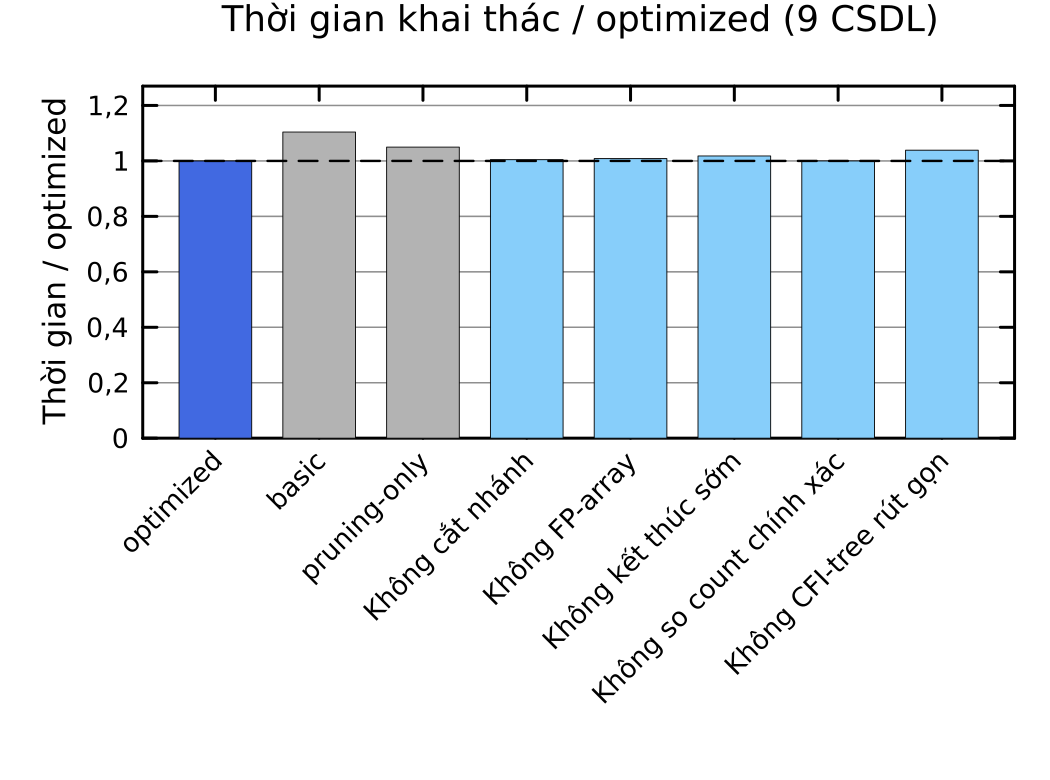

| Dataset | optimized (s) | basic | pruning- only | Không cắt nhánh | Không FP-array | Không kết thúc sớm | Không so count chính xác | Không CFI-tree rút gọn |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| chess | 0,071 | 1,21 | 1,22 | 0,99 | 1,01 | 1,04 | 1,00 | 1,21 |
| mushrooms | 0,084 | 1,44 | 1,10 | 1,16 | 1,05 | 1,09 | 1,01 | 1,14 |
| connect | 0,230 | 1,07 | 1,03 | 0,93 | 0,99 | 0,94 | 0,96 | 0,98 |
| pumsb_star | 0,142 | 1,01 | 1,01 | 1,05 | 1,01 | 1,04 | 1,07 | 1,07 |
| accidents | 0,456 | 1,00 | 1,03 | 1,01 | 0,99 | 1,00 | 1,00 | 1,00 |
| retail | 0,302 | 1,00 | 1,02 | 0,97 | 1,00 | 0,98 | 0,97 | 0,95 |
| T10I4D100K | 0,881 | 0,98 | 1,01 | 0,97 | 1,01 | 1,01 | 1,00 | 0,99 |
| T40I10D100K | 4,822 | 1,17 | 1,12 | 0,96 | 1,14 | 0,98 | 1,02 | 0,97 |
| kosarak | 1,779 | 1,11 | 0,92 | 1,00 | 0,90 | 1,08 | 0,98 | 1,06 |


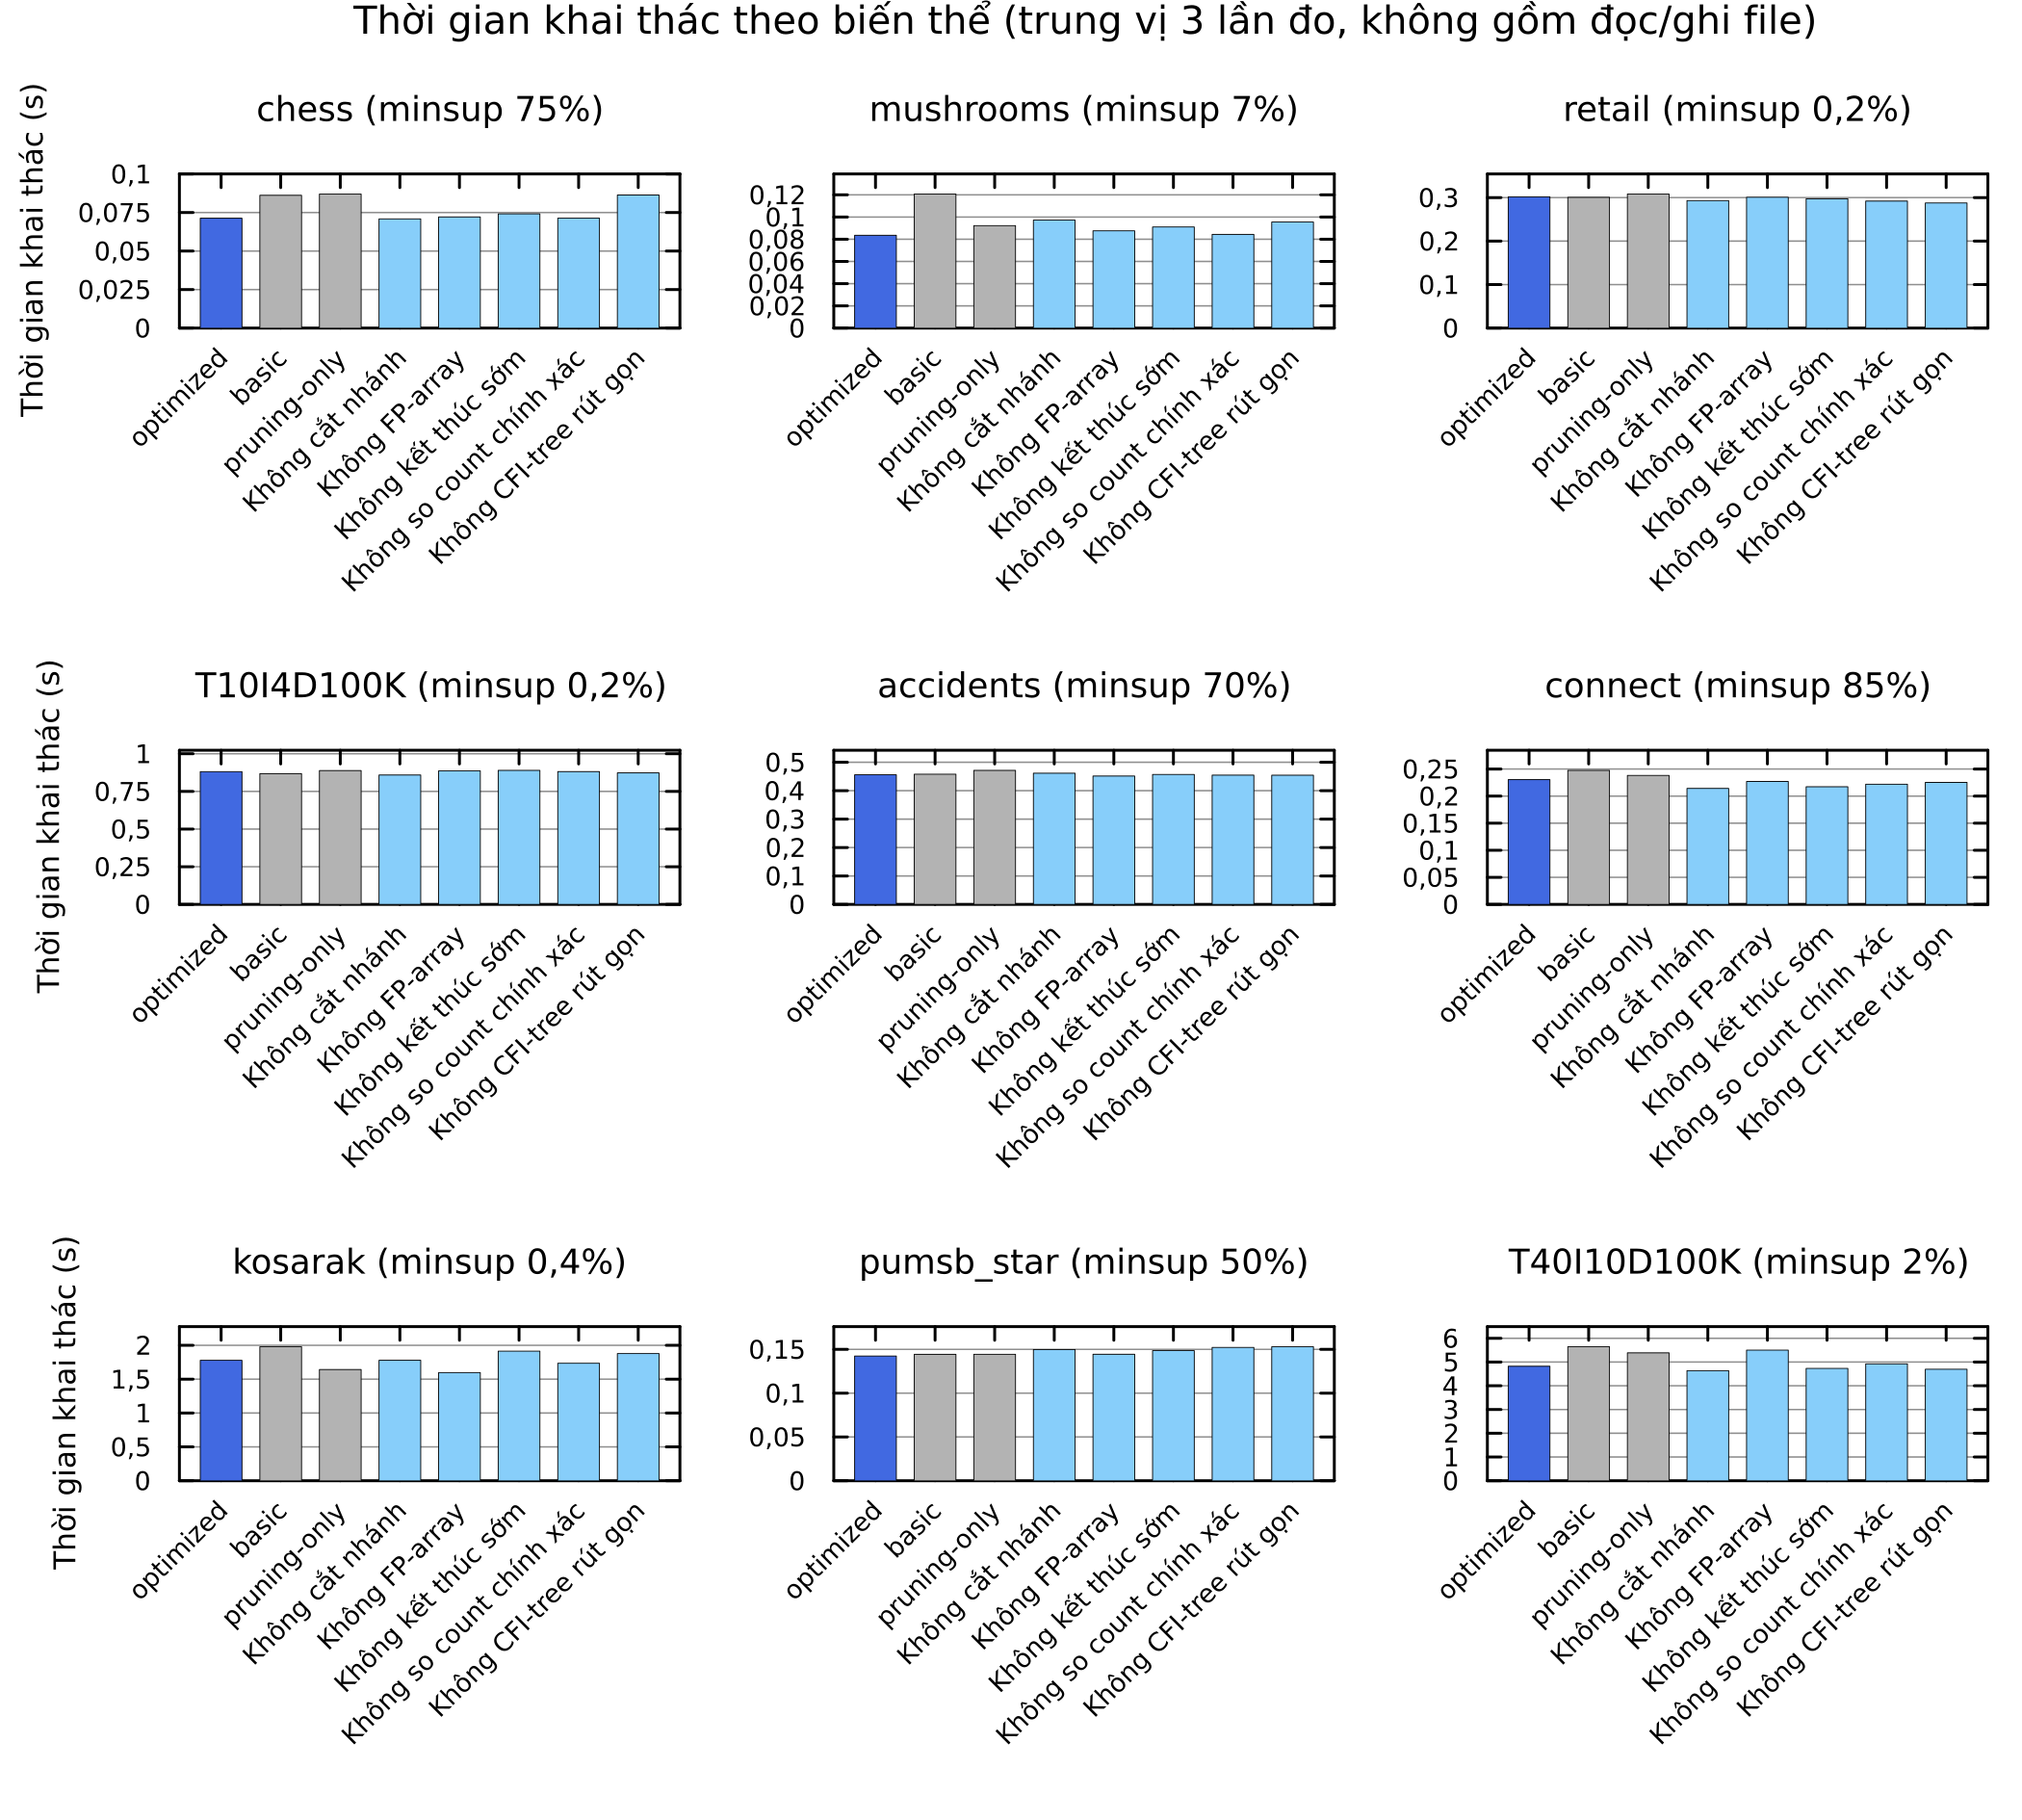

In [9]:
show_figure("ablation_time_relative")
show_md(tables.ablation)
show_figure("time_variants_grid")

### Nhận xét

- **RAM tối đa** ít thay đổi giữa basic và optimized: bản optimized giảm nhẹ trên retail (368 xuống 361 MB) và
  T10I4D100K (621 xuống 613 MB), trên các CSDL còn lại chênh lệch không quá 5 MB.
- RAM tối đa đi từ khoảng 297 MB trên các CSDL dày nhỏ (gần bằng mức sau warm-up) đến khoảng 1,96 GB trên T40I10D100K,
  nơi FP-tree gốc gần như không nén được (khoảng 3,26 triệu nút, $R_{\text{tree}} = 89\%$) và giao dịch dài (trung bình
  39,6 item).
- **Thời gian khai thác** basic/optimized đi từ 0,98 trên T10I4D100K (trong phạm vi nhiễu) đến 1,44 trên mushrooms, tức
  bản optimized giảm khoảng 31% thời gian khai thác trên mushrooms.
- **FP-array:** tắt làm thời gian khai thác trên T40I10D100K tăng 14% nhưng trên kosarak lại giảm 10%. FP-array chỉ được
  dùng trên dữ liệu thưa (941 lần trên retail, 727 lần trên T40I10D100K, 0 lần trên mọi CSDL dày) vì nó bị tắt khi
  cây đủ dày, đúng như bài báo đề xuất.
- **Cắt nhánh và kết thúc sớm** giảm số lời gọi đệ quy trên dữ liệu dày (mushrooms từ 15.095 xuống 8.158, connect từ
  13.362 xuống 8.212); tắt **CFI-tree rút gọn** làm thời gian khai thác tăng 21% trên chess và 14% trên mushrooms.
- Các chênh lệch dưới khoảng 10% được diễn giải thận trọng vì mỗi cấu hình chỉ có ba lần đo.

## 5 · Khả năng mở rộng (scalability)

**Đề:** chọn một tập dữ liệu lớn (Retail hoặc Accidents), tạo tập con 10%, 25%, 50%, 75%, 100% giao dịch; vẽ thời gian
chạy theo kích thước CSDL; nhận xét xu hướng tuyến tính hay phi tuyến.

**Cách đo:** `results/scalability/scalability.csv` trên các tập con lồng nhau `data/scalability/retail_p010..p100.txt`
(xáo trộn một lần với seed 2026 rồi lấy tiền tố), hai mức minsup tương đối 0,1% và 0,05%. Hình vẽ thời gian (trung vị
3 lần đo, gồm đọc và ghi file) theo phần trăm giao dịch; trục tung tuyến tính.

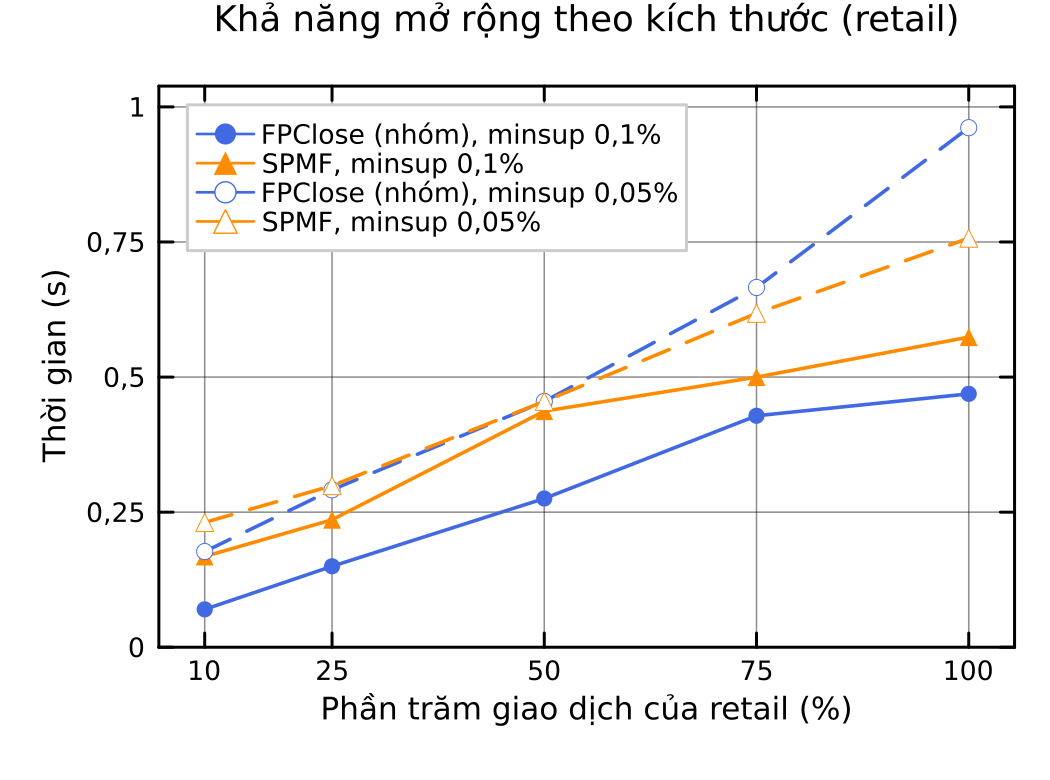

| Kích thước | Giao dịch | Nhóm 0,1% | SPMF 0,1% | Nhóm 0,05% | SPMF 0,05% |
|---|---:|---:|---:|---:|---:|
| 10% | 8 816 | 0,070 | 0,168 | 0,177 | 0,231 |
| 25% | 22 040 | 0,150 | 0,236 | 0,291 | 0,299 |
| 50% | 44 081 | 0,275 | 0,437 | 0,455 | 0,455 |
| 75% | 66 121 | 0,428 | 0,500 | 0,666 | 0,618 |
| 100% | 88 162 | 0,469 | 0,574 | 0,962 | 0,757 |


In [10]:
show_figure("scalability_time")
show_md(scalability_table())

### Nhận xét

- Số tập đóng gần ổn định giữa các tập con (7.572–8.394 ở minsup 0,1% và 18.925–19.579 ở 0,05%), nên không gian khai
  thác ít thay đổi theo kích thước.
- Khi số giao dịch tăng 10 lần, thời gian của nhóm tăng 6,7 lần (0,1%) và 5,4 lần (0,05%), của SPMF tăng 3,4 và 3,3 lần.
- Mô hình tuyến tính $T(n) = an + b$ khớp tốt cho cả hai cài đặt ($R^2 \ge 0{,}95$), gợi ý xu hướng gần tuyến tính
  trong phạm vi khảo sát. Hệ số chặn $b$ của SPMF là 0,14–0,16 s (21–25% thời gian ở 100%), của nhóm là 0,04–0,07 s (7–8%).
- Ở minsup 0,1%, nhóm nhanh hơn SPMF ở mọi kích thước (0,42–0,86). Ở 0,05%, nhóm nhanh hơn ở 10% (0,77), gần tương
  đương từ 25% đến 75% (0,97–1,08) và chậm hơn trên toàn bộ retail (0,96 so với 0,76 s, tỉ lệ 1,27).
- Chi phí đọc dữ liệu và dựng FP-tree gốc tăng theo tổng số lượt item, tức tỉ lệ với số giao dịch; phần tăng thời gian
  chủ yếu đến từ khối lượng dữ liệu, phù hợp với xu hướng gần tuyến tính.

## 6 · Ảnh hưởng của độ dài giao dịch trung bình

**Đề:** nếu thuật toán bị ảnh hưởng bởi độ dài giao dịch, thiết kế thực nghiệm minh chứng bằng CSDL tổng hợp có độ dài
giao dịch tăng dần.

**Cách đo:** `results/txlen/txlen.csv` trên `data/synthetic/len05..len30.txt` (10.000 giao dịch, 500 item, độ dài
trung bình 5 đến 30; giao dịch của mức dài chứa giao dịch của mức ngắn), hai mức minsup 0,5% và 0,2%. Hình
`txlen_time` vẽ thời gian (trục tung thang log), hình `txlen_itemsets` vẽ số closed itemset.

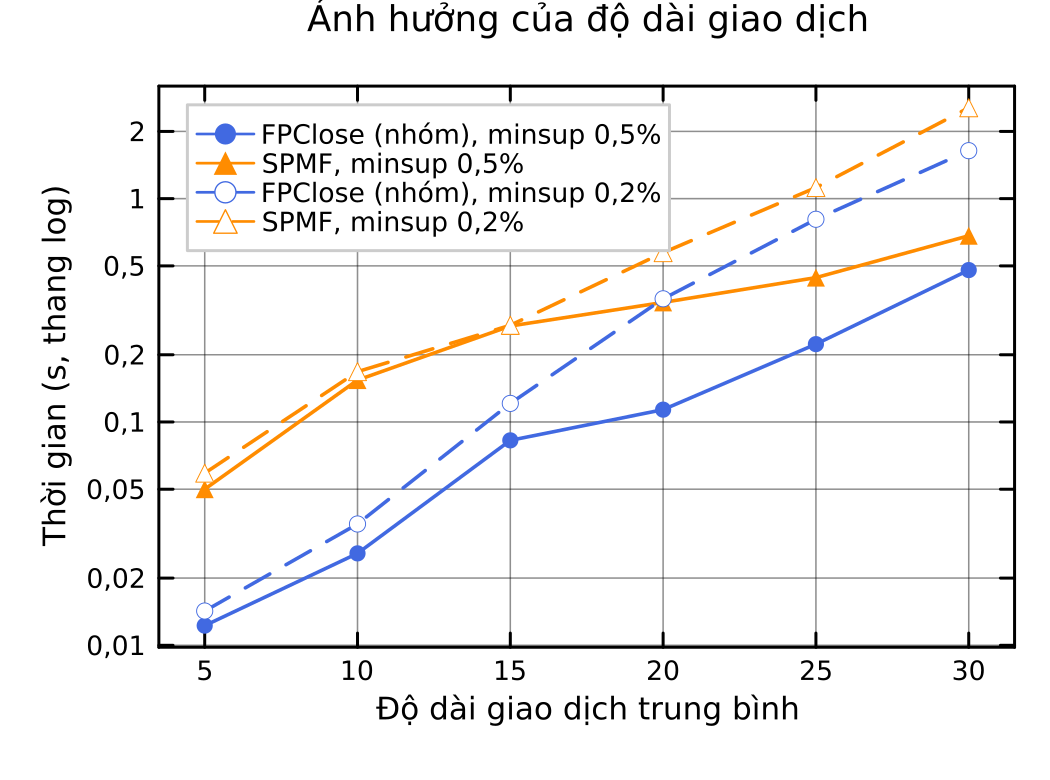

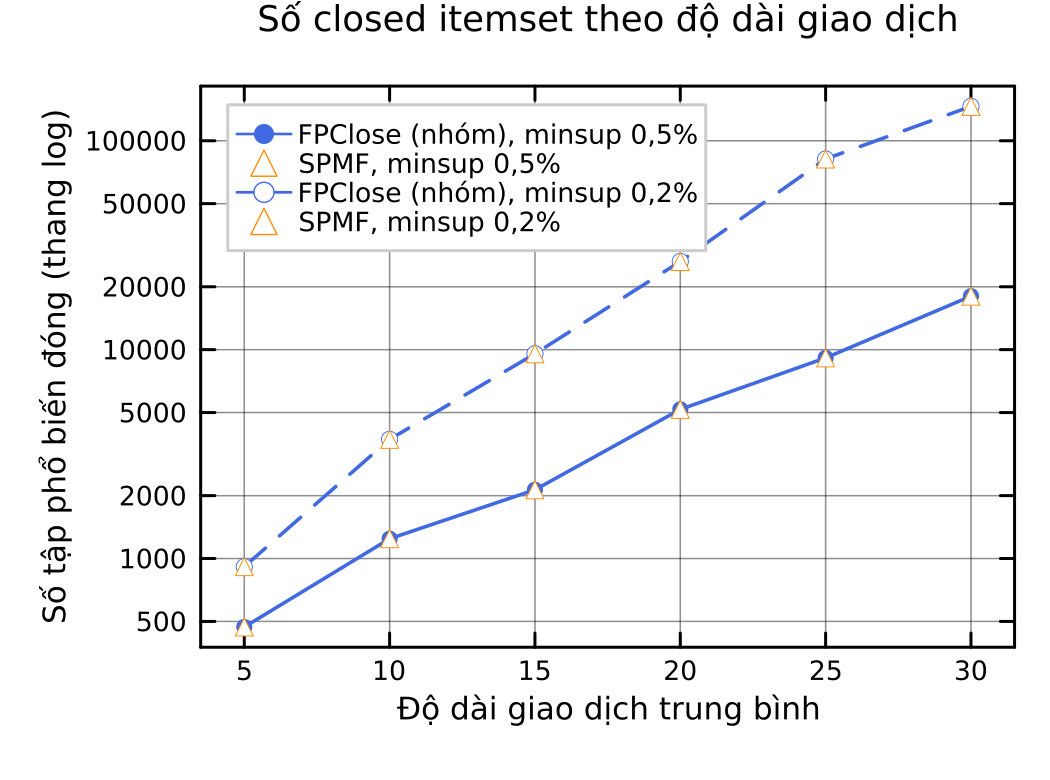

| Độ dài TB | minsup | Closed itemsets | Nhóm (s) | SPMF (s) | Nhóm / SPMF |
|---:|---:|---:|---:|---:|---:|
| 5 | 0,5% | 470 | 0,012 | 0,050 | 0,24 |
| 5 | 0,2% | 914 | 0,014 | 0,059 | 0,24 |
| 10 | 0,5% | 1 244 | 0,026 | 0,154 | 0,17 |
| 10 | 0,2% | 3 720 | 0,035 | 0,168 | 0,21 |
| 15 | 0,5% | 2 134 | 0,083 | 0,269 | 0,31 |
| 15 | 0,2% | 9 556 | 0,121 | 0,271 | 0,45 |
| 20 | 0,5% | 5 177 | 0,114 | 0,343 | 0,33 |
| 20 | 0,2% | 26 428 | 0,356 | 0,573 | 0,62 |
| 25 | 0,5% | 9 135 | 0,223 | 0,443 | 0,50 |
| 25 | 0,2% | 81 828 | 0,808 | 1,121 | 0,72 |
| 30 | 0,5% | 18 038 | 0,479 | 0,682 | 0,70 |
| 30 | 0,2% | 146 134 | 1,640 | 2,552 | 0,64 |


In [11]:
show_figure("txlen_time")
show_figure("txlen_itemsets")
show_md(txlen_table())

### Nhận xét

- Khi độ dài trung bình tăng từ 5 lên 30, số tập đóng tăng khoảng 38 lần (470 lên 18.038) ở minsup 0,5% và 160 lần
  (914 lên 146.134) ở 0,2%.
- Thời gian của nhóm tăng tương ứng khoảng 39 lần (0,012 lên 0,48 s) và 115 lần (0,014 lên 1,64 s), cùng chiều với số
  tập đóng. Sáu điểm đo không đủ để khẳng định một quy luật hàm mũ.
- Giải thích: độ dài giao dịch sau lọc tăng làm tăng chi phí sắp xếp và chèn từng giao dịch, kích thước pattern base và
  số cây điều kiện phải dựng; với giao dịch dài, nhiều tổ hợp item cùng đạt minsup hơn nên không gian khai thác mở rộng
  nhanh.
- Nhóm nhanh hơn SPMF ở mọi cấu hình (tỉ lệ 0,17–0,72), nhưng lợi thế thu hẹp khi giao dịch dài ra: ở minsup 0,5%, tỉ
  lệ tăng từ 0,24 ở độ dài 5 lên 0,70 ở độ dài 30.

## 7 · Đánh giá chung và hướng tối ưu

- **Điểm mạnh:** cài đặt của nhóm khớp SPMF trên cả 56 cấu hình closed itemset; nhóm nhanh hơn SPMF ở 44/56 cấu hình
  minsup, gồm mọi mức trên cả năm CSDL dày (tới khoảng 9 lần trên chess 60%), và ở cả 12 cấu hình độ dài giao dịch.
  Bộ đọc file theo byte nhanh hơn bộ đọc theo dòng trước đó 7,9–19,9 lần trên chín CSDL (accidents từ 1,42 xuống 0,08 s).
- **Điểm yếu:** nhóm vẫn chậm hơn SPMF trên một số CSDL thưa tại minsup thấp (retail 0,05–0,02%, T10I4D100K ở 0,5% và
  từ 0,1% trở xuống, T40I10D100K 1,25%), với tỉ lệ thời gian lên đến 1,49. Dựng cây và khai thác chiếm phần lớn thời
  gian thực thi; hiệu quả của FP-array phụ thuộc CSDL (có lợi trên T40I10D100K nhưng làm chậm kosarak).
- **Giới hạn:** kết quả chỉ phản ánh các cấu hình khảo sát; ba lần đo mỗi cấu hình, cách warm-up khác nhau giữa Julia
  và JVM, và việc khảo sát khả năng mở rộng chỉ trên retail giới hạn khả năng suy rộng.
- **Hướng tối ưu 1 – Giảm cấp phát khi dựng cây:** thay các nút là đối tượng riêng bằng cấu trúc mảng (*struct of
  arrays*: mảng item, count, cha, node-link dạng `Int32`) và tái sử dụng vùng nhớ theo vòng đời của từng tầng đệ quy;
  cần đo lại bộ nhớ cấp phát và RAM tối đa khi triển khai.
- **Hướng tối ưu 2 – FP-array thích nghi:** tắt FP-array giảm 10% thời gian khai thác trên kosarak nhưng tăng 14% trên
  T40I10D100K; có thể quyết định bật hay tắt FP-array cho từng cây điều kiện theo số item, tỉ lệ nén thực đo và ngân sách
  bộ nhớ, thay cho các ngưỡng cố định hiện tại (`dense_ratio`, `skip_items`). Hướng này chưa được triển khai và kiểm chứng.